In [ ]:
https://github.com/iandriyash/ai-arhictect-2026-demo/tree/main

# Домашнее задание: Ridge и Lasso

**Датасет:** витрина из 1-й промежуточной аттестации (`loan_overdue_mart.csv`).

**Цель:** выбрать непрерывный таргет, посмотреть форму связи, разделить выборку, масштабировать признаки, обучить Ridge и Lasso на разных спецификациях, сравнить качество на тесте и выбрать лучшую.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, LinearRegression, ElasticNet
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Таргет и признаки

**Таргет:** `principal_amount` — сумма кредита (непрерывная).

**Признаки:** доход, возраст, ставка, срок; продукт и статус занятости — через dummy.

В прошлой домашке полная OLS-модель страдала от мультиколлинеарности (срок / ставка / продукт). Здесь смотрим, помогает ли регуляризация.

In [2]:
df = pd.read_csv("loan_overdue_mart.csv")
work = df[[
    "principal_amount", "annual_income", "customer_age",
    "interest_rate", "term_months", "loan_product_id", "employment_status_id",
]].dropna().copy()

work["product_2"] = (work["loan_product_id"] == 2).astype(int)
work["emp_2"] = (work["employment_status_id"] == 2).astype(int)
work["emp_3"] = (work["employment_status_id"] == 3).astype(int)
work["emp_4"] = (work["employment_status_id"] == 4).astype(int)

print("Строк:", len(work))
work[["principal_amount", "annual_income", "customer_age", "interest_rate", "term_months"]].describe()

Строк: 2477


,principal_amount,annual_income,customer_age,interest_rate,term_months
count,"2,477.000","2,477.000","2,477.000","2,477.000","2,477.000"
mean,"2,769,276.638","2,296,362.461",44.791,17.361,104.623
std,"2,994,147.858","1,339,002.497",12.030,4.426,96.452
min,"100,915.730",0.000,18.000,10.008,12.000
25%,"557,503.570","1,419,009.480",35.000,13.278,36.000
50%,"1,042,061.940","1,964,831.280",44.000,17.603,60.000
75%,"4,960,516.990","2,762,145.960",54.000,21.157,180.000
max,"9,980,470.050","8,476,093.680",80.000,24.996,300.000


## 2. Точечные диаграммы и форма связи

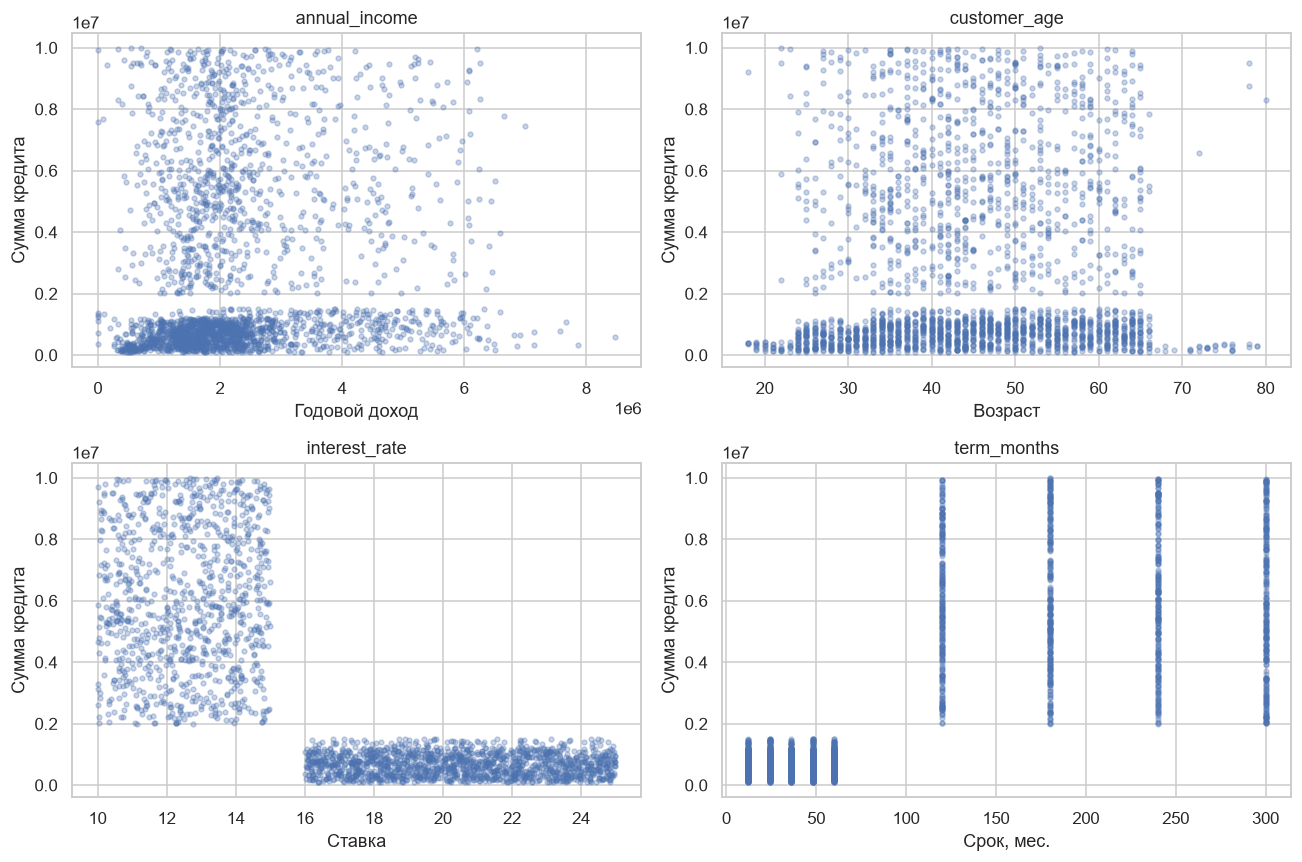

Корреляция с таргетом:
principal_amount    1.000
annual_income       0.107
customer_age        0.053
interest_rate      -0.752
term_months         0.773
Name: principal_amount, dtype: float64


In [3]:
features = ["annual_income", "customer_age", "interest_rate", "term_months"]
titles = {
    "annual_income": "Годовой доход",
    "customer_age": "Возраст",
    "interest_rate": "Ставка",
    "term_months": "Срок, мес.",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()
for ax, feat in zip(axes, features):
    ax.scatter(work[feat], work["principal_amount"], alpha=0.3, s=10, color="#4C72B0")
    ax.set_xlabel(titles[feat])
    ax.set_ylabel("Сумма кредита")
    ax.set_title(feat)
plt.tight_layout()
plt.show()

print("Корреляция с таргетом:")
print(work[["principal_amount"] + features].corr()["principal_amount"].round(3))

**Форма связи:**
- срок — сильная положительная линейная;
- ставка — сильная отрицательная;
- доход — слабая положительная, облако размытое;
- возраст — почти нет связи.

Между признаками: срок и продукт ≈ 0.89, ставка и продукт ≈ −0.87, срок и ставка ≈ −0.78. Это мультиколлинеарность.

## 3. Разделение и масштабирование

In [4]:
def split_train_test(data, features, target, test_size=0.25, random_state=42):
    X = data[features]
    y = data[target]
    return train_test_split(X, y, test_size=test_size, random_state=random_state)

feat_all = [
    "annual_income", "customer_age", "interest_rate", "term_months",
    "product_2", "emp_2", "emp_3", "emp_4",
]
target_col = "principal_amount"

X_train, X_test, y_train, y_test = split_train_test(work, feat_all, target_col)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1857, 8) Test: (620, 8)


## 4. Обучение моделей

Сравниваем OLS, Ridge и Lasso с разными α.  
Метрики: R², RMSE, MAE, MAPE. Считаются на тестовой выборке.

In [5]:
def get_predictions(model, X):
    return model.predict(X)

def show_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    print(f"MSE:  {mse:,.0f}")
    print(f"RMSE: {np.sqrt(mse):,.0f}")
    print(f"MAE:  {mean_absolute_error(y_true, y_pred):,.0f}")
    print(f"MAPE: {mean_absolute_percentage_error(y_true, y_pred):.3f}")
    print(f"R2:   {r2_score(y_true, y_pred):.3f}")

def eval_model(name, model):
    model.fit(X_train_s, y_train)
    pred = get_predictions(model, X_test_s)
    return {
        "model": name,
        "r2": r2_score(y_test, pred),
        "rmse": np.sqrt(mean_squared_error(y_test, pred)),
        "mae": mean_absolute_error(y_test, pred),
        "mape": mean_absolute_percentage_error(y_test, pred),
        "n_nonzero": int(np.sum(np.abs(model.coef_) > 1e-4)),
        "estimator": model,
        "pred": pred,
    }

results = []
results.append(eval_model("OLS", LinearRegression()))

for a in [0.1, 1.0, 10.0, 100.0]:
    results.append(eval_model(f"Ridge α={a}", Ridge(alpha=a)))

for a in [1_000, 10_000, 50_000, 100_000]:
    results.append(eval_model(f"Lasso α={a}", Lasso(alpha=a, max_iter=20_000)))

# Дополнительно ElasticNet
results.append(eval_model("ElasticNet α=0.1", ElasticNet(alpha=0.1, max_iter=20_000)))

res_df = pd.DataFrame(results)[["model", "r2", "rmse", "mae", "mape", "n_nonzero"]]
print(res_df.round(3).to_string(index=False))

           model    r2          rmse         mae  mape  n_nonzero
             OLS 0.774 1,471,158.265 935,221.085 0.569          8
     Ridge α=0.1 0.774 1,471,123.432 935,186.959 0.569          8
     Ridge α=1.0 0.774 1,470,818.218 934,891.958 0.570          8
    Ridge α=10.0 0.775 1,468,505.017 933,235.884 0.577          8
   Ridge α=100.0 0.772 1,477,565.803 955,868.491 0.667          8
    Lasso α=1000 0.774 1,470,399.571 934,768.605 0.570          8
   Lasso α=10000 0.776 1,463,806.733 931,420.804 0.577          7
   Lasso α=50000 0.776 1,463,837.746 933,239.767 0.606          3
  Lasso α=100000 0.773 1,473,217.719 942,070.976 0.644          1
ElasticNet α=0.1 0.773 1,476,005.159 953,330.864 0.660          8


## 4.1 Разные наборы признаков

В разделе 4 варьировался только α на одном фиксированном наборе признаков. Задание просит сравнить ещё и разные наборы переменных, поэтому беру лучшие по предыдущей таблице модели (Ridge α=10, Lasso α=10000) и прогоняю их на трёх спецификациях:

1. только `interest_rate` + `term_months` — самые сильные предикторы по корреляции;
2. все признаки, кроме `product_2` — чтобы отдельно увидеть вклад продукта;
3. полный набор (как в разделе 4).


In [6]:
spec_defs = {
    "Срок + ставка": ["interest_rate", "term_months"],
    "Без product_2": ["annual_income", "customer_age", "interest_rate", "term_months", "emp_2", "emp_3", "emp_4"],
    "Все признаки": feat_all,
}

spec_rows = []
for spec_name, spec_feats in spec_defs.items():
    Xtr = X_train[spec_feats]
    Xte = X_test[spec_feats]
    spec_scaler = StandardScaler()
    Xtr_s = spec_scaler.fit_transform(Xtr)
    Xte_s = spec_scaler.transform(Xte)

    for model_name, model in [("Ridge α=10", Ridge(alpha=10.0)), ("Lasso α=10000", Lasso(alpha=10_000.0, max_iter=20_000))]:
        model.fit(Xtr_s, y_train)
        pred = model.predict(Xte_s)
        spec_rows.append({
            "спецификация": spec_name,
            "модель": model_name,
            "r2": r2_score(y_test, pred),
            "rmse": np.sqrt(mean_squared_error(y_test, pred)),
            "mae": mean_absolute_error(y_test, pred),
            "mape": mean_absolute_percentage_error(y_test, pred),
            "n_nonzero": int(np.sum(np.abs(model.coef_) > 1e-4)),
        })

spec_df = pd.DataFrame(spec_rows)
print(spec_df.round(3).to_string(index=False))

 спецификация        модель    r2          rmse           mae  mape  n_nonzero
Срок + ставка    Ridge α=10 0.694 1,712,919.028 1,260,056.473 1.251          2
Срок + ставка Lasso α=10000 0.694 1,713,269.184 1,259,855.600 1.250          2
Без product_2    Ridge α=10 0.693 1,715,219.387 1,260,795.061 1.245          7
Без product_2 Lasso α=10000 0.693 1,714,148.258 1,259,178.667 1.241          7
 Все признаки    Ridge α=10 0.775 1,468,505.017   933,235.884 0.577          8
 Все признаки Lasso α=10000 0.776 1,463,806.733   931,420.804 0.577          7


Без `product_2` качество падает почти до уровня модели «срок + ставка» (R² ≈ 0.69 вместо ≈ 0.78), а MAPE резко растёт (≈ 0.58 → ≈ 1.25). Значит, в полной модели основной прирост качества даёт именно `product_2`, а не срок и ставка сами по себе — они дают base-эффект, а продукт добавляет сегментацию поверх него.

## 5. Выбор спецификации и проверка на тесте

In [7]:
best = max(results, key=lambda x: x["r2"])
print("Лучшая по R²:", best["model"])
print()
show_metrics(y_test, best["pred"])
print("Ненулевых коэффициентов:", best["n_nonzero"])

Лучшая по R²: Lasso α=10000

MSE:  2,142,730,150,333
RMSE: 1,463,807
MAE:  931,421
MAPE: 0.577
R2:   0.776
Ненулевых коэффициентов: 7


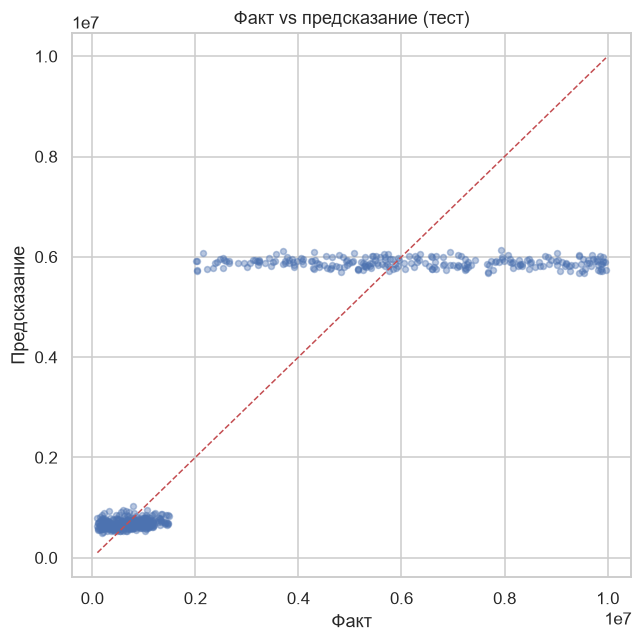

In [8]:
# Визуализация предсказаний
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best["pred"], alpha=0.4, s=15)
lims = [min(y_test.min(), best["pred"].min()), max(y_test.max(), best["pred"].max())]
plt.plot(lims, lims, "r--", lw=1)
plt.xlabel("Факт")
plt.ylabel("Предсказание")
plt.title("Факт vs предсказание (тест)")
plt.tight_layout()
plt.show()

In [9]:
# Коэффициенты
coef_df = pd.DataFrame(
    index=feat_all,
    data=best["estimator"].coef_,
    columns=["coef"],
)
print(coef_df.round(0).T)

      annual_income  customer_age  interest_rate  term_months     product_2  \
coef     65,207.000    45,489.000         -0.000  -78,022.000 2,608,987.000   

         emp_2      emp_3       emp_4  
coef 1,876.000 23,020.000 -13,189.000  


## 5.1 Сравнение коэффициентов по моделям


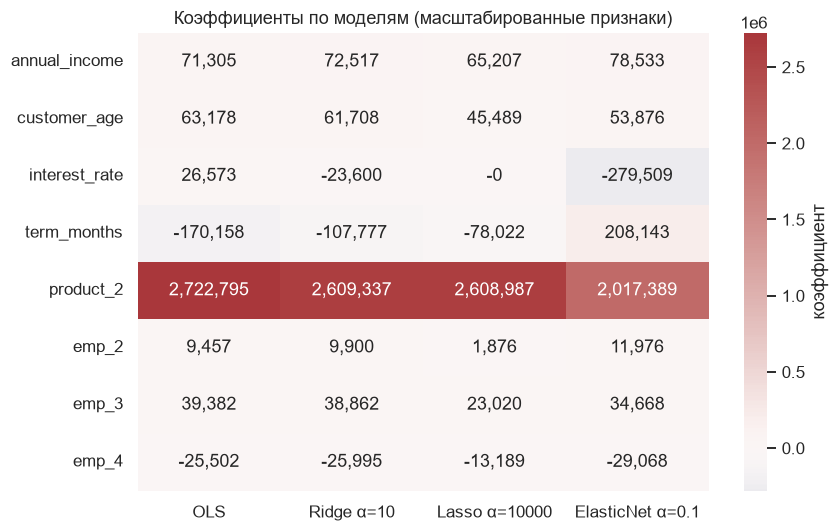

In [10]:
models_coef = {
    "OLS": LinearRegression(),
    "Ridge α=10": Ridge(alpha=10.0),
    "Lasso α=10000": Lasso(alpha=10_000.0, max_iter=20_000),
    "ElasticNet α=0.1": ElasticNet(alpha=0.1, max_iter=20_000),
}

coef_matrix = pd.DataFrame(index=feat_all)
for name, model in models_coef.items():
    model.fit(X_train_s, y_train)
    coef_matrix[name] = model.coef_

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(coef_matrix, annot=True, fmt=",.0f", cmap="vlag", center=0,
            cbar_kws={"label": "коэффициент"}, ax=ax)
ax.set_title("Коэффициенты по моделям (масштабированные признаки)")
plt.tight_layout()
plt.show()

На тепловой карте `product_2` — единственная строка, где цвет и значение почти не меняются между столбцами: во всех четырёх моделях коэффициент около +2.0…+2.7 млн. `term_months` и `interest_rate`, наоборот, видно прыгают от синего к красному и обратно между моделями — это и есть нестабильность из-за мультиколлинеарности, о которой написано в выводах ниже. Остальные признаки (доход, возраст, занятость) бледные и стабильные по знаку, но малы по величине.

## 5.2 Путь коэффициентов

Показываю, как коэффициенты меняются при росте штрафа α (шкала α логарифмическая, по оси Y — symlog, чтобы были видны и малые коэффициенты рядом с `product_2`). Пунктир — выбранные ранее α (Ridge 10, Lasso 10000).

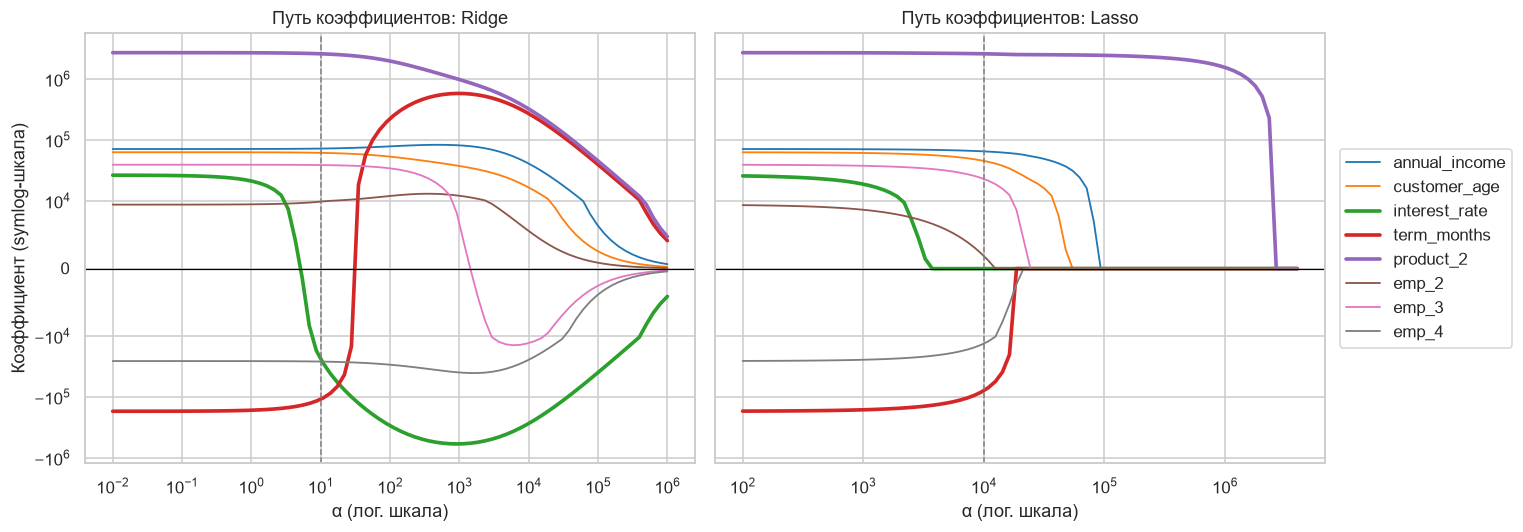

In [11]:
ridge_alphas = np.logspace(-2, 6, 80)
lasso_alphas = np.logspace(2, 6.6, 80)

ridge_path = np.array([Ridge(alpha=a).fit(X_train_s, y_train).coef_ for a in ridge_alphas])
lasso_path = np.array([Lasso(alpha=a, max_iter=100_000).fit(X_train_s, y_train).coef_ for a in lasso_alphas])

colors = dict(zip(feat_all, sns.color_palette("tab10", len(feat_all))))
key_feats = {"term_months", "interest_rate", "product_2"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
panels = [
    (axes[0], ridge_alphas, ridge_path, "Путь коэффициентов: Ridge", 10.0),
    (axes[1], lasso_alphas, lasso_path, "Путь коэффициентов: Lasso", 10_000.0),
]
for ax, alphas, path, title, chosen in panels:
    for j, f in enumerate(feat_all):
        ax.plot(alphas, path[:, j], label=f, color=colors[f], lw=2.4 if f in key_feats else 1.2)
    ax.set_xscale("log")
    ax.set_yscale("symlog", linthresh=1e4)
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(chosen, color="gray", ls="--", lw=1)
    ax.set_xlabel("α (лог. шкала)")
    ax.set_title(title)
axes[0].set_ylabel("Коэффициент (symlog-шкала)")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

**Ridge.** Коэффициенты плавно сжимаются к нулю, но не обнуляются. При этом `interest_rate` меняет знак с плюса на минус около α ≈ 4–5, а `term_months` — с минуса на плюс около α ≈ 28–35: две линии зеркально расходятся в разные стороны и на α порядка 1000 достигают ≈ ±0.58 млн. Выбранный Ridge α=10 стоит как раз между этими двумя переходами, то есть на участке, где знаки уже не те, что у OLS.

**Lasso.** Признаки обнуляются по очереди: сначала `interest_rate` (α порядка 4 тыс.), затем занятость и `term_months` (порядка 12–25 тыс.), потом возраст и доход (≈ 55 и ≈ 93 тыс.), и последним — `product_2` (≈ 2.7 млн). Выбранный α=10000 уже после обнуления ставки, но до обнуления срока.

Оба графика показывают то же, что и тепловая карта: устойчив только `product_2`, а линии `term_months` и `interest_rate` ведут себя зеркально и сильно зависят от α.

## 6. Выводы

**Качество.**  
Лучшая модель по R² — Lasso α=10000 на полном наборе признаков (R² ≈ 0.776). Она немного обгоняет OLS и Ridge на тесте и при этом обнуляет один коэффициент (`interest_rate`).

**Что сделала регуляризация.**  
Lasso обнулил ставку — признак, сильно связанный с продуктом и сроком (корреляции ≈ −0.87 и ≈ −0.78). Тем самым он убрал один из источников мультиколлинеарности, не потеряв в качестве. Ridge сжимал веса, но ничего не обнулял (все 8 коэффициентов остались ненулевыми). ElasticNet (α=0.1) здесь не промежуточный вариант: его R² ≈ 0.773 — второй худший результат среди всех проверенных моделей (хуже обычного OLS), и коэффициенты он не обнулил ни одного — по качеству и по разреженности он ближе к слабому Ridge, чем к Lasso.

**Интерпретация и устойчивость.**  
После масштабирования коэффициенты сопоставимы не везде: `product_2` даёт эффект на порядок-два больше остальных (≈ 2.6 млн против десятков тысяч у прочих признаков) и во всех спецификациях остаётся главным источником сигнала.

Знаки `term_months` и `interest_rate` при этом неустойчивы между методами на одной и той же спецификации: term_months идёт от −170 тыс. (OLS) к −108 тыс. (Ridge) и −78 тыс. (Lasso), а у ElasticNet вообще меняет знак на +208 тыс.; то же со ставкой (от +27 тыс. у OLS до −280 тыс. у ElasticNet, у Lasso — обнулена). Это тот же эффект мультиколлинеарности, что и в прошлой домашке с OLS, только здесь он проявляется и после регуляризации — поэтому знак и величину этих двух коэффициентов не стоит трактовать буквально, устойчив по факту только эффект `product_2`.

Путь коэффициентов (раздел 5.2) показывает то же по α: у Ridge знаки ставки и срока меняются при росте штрафа, у Lasso ставка обнуляется первой, а `product_2` — последним.

Доход и возраст — небольшой, но стабильный по знаку положительный эффект во всех моделях.

**Сравнение спецификаций (раздел 4.1).**  
Без `product_2` качество падает почти до уровня модели «только срок + ставка» (R² ≈ 0.69 против ≈ 0.78 у полного набора) — значит, основной прирост полной модели даёт именно продукт, а не срок и ставка по отдельности.

**Практический вывод.**  
Регуляризация не столько «оставляет все признаки и убирает лишние», сколько показывает, какие коэффициенты можно доверять: `product_2` устойчив во всех моделях и спецификациях, `interest_rate` и `term_months` — нет, их знак и масштаб зависят от метода. Для этой задачи Lasso с умеренным α даёт лучшее сочетание качества и интерпретируемости. MAPE у полной модели (≈ 0.58) ощутимо ниже, чем у урезанных спецификаций (≈ 1.25) — большая ошибка в процентах там связана в основном с отсутствием `product_2`, а не с общим ограничением линейной модели на этих данных.